In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# Load the hospital dataset
df = pd.read_csv("hospital_synthetic_dataset.xlsx.csv")

# Display the first five rows
df.head()

,age,sex,blood_pressure,cholesterol,bmi,smoker,diabetes,physical_activity,family_history,stress_level,heart_disease
0,68,Male,105,191,38.0,Yes,Yes,0,No,2,0
1,58,Female,97,249,22.0,Yes,Yes,0,No,4,0
2,44,Female,93,190,23.2,No,Yes,0,No,8,0
3,72,Male,93,183,39.4,No,No,3,Yes,1,0
4,37,Female,145,166,22.0,No,Yes,4,Yes,1,0


In [7]:
# Check the size of the dataset
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (500, 11)

Column Names:
['age', 'sex', 'blood_pressure', 'cholesterol', 'bmi', 'smoker', 'diabetes', 'physical_activity', 'family_history', 'stress_level', 'heart_disease']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                500 non-null    int64  
 1   sex                500 non-null    str    
 2   blood_pressure     500 non-null    int64  
 3   cholesterol        500 non-null    int64  
 4   bmi                500 non-null    float64
 5   smoker             500 non-null    str    
 6   diabetes           500 non-null    str    
 7   physical_activity  500 non-null    int64  
 8   family_history     500 non-null    str    
 9   stress_level       500 non-null    int64  
 10  heart_disease      500 non-null    int64  
dtypes: float64(1), int64(6), str(4)
memory usage: 43.1 KB

Missing Val

In [8]:
print(df['heart_disease'].value_counts())

print("\nPercentage Distribution:")
print(df['heart_disease'].value_counts(normalize=True) * 100)

heart_disease
1    266
0    234
Name: count, dtype: int64

Percentage Distribution:
heart_disease
1    53.2
0    46.8
Name: proportion, dtype: float64


In [9]:
categorical_columns = ['sex', 'smoker', 'diabetes', 'family_history']

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())



sex:
sex
Female    266
Male      234
Name: count, dtype: int64

smoker:
smoker
Yes    266
No     234
Name: count, dtype: int64

diabetes:
diabetes
No     263
Yes    237
Name: count, dtype: int64

family_history:
family_history
No     261
Yes    239
Name: count, dtype: int64


In [10]:
# Convert categorical columns into numerical values

df['sex'] = df['sex'].map({'Female': 0, 'Male': 1})

df['smoker'] = df['smoker'].map({'No': 0, 'Yes': 1})

df['diabetes'] = df['diabetes'].map({'No': 0, 'Yes': 1})

df['family_history'] = df['family_history'].map({'No': 0, 'Yes': 1})

# Display the updated dataset
df.head()

,age,sex,blood_pressure,cholesterol,bmi,smoker,diabetes,physical_activity,family_history,stress_level,heart_disease
0,68,1,105,191,38.0,1,1,0,0,2,0
1,58,0,97,249,22.0,1,1,0,0,4,0
2,44,0,93,190,23.2,0,1,0,0,8,0
3,72,1,93,183,39.4,0,0,3,1,1,0
4,37,0,145,166,22.0,0,1,4,1,1,0


In [11]:
# Check the data types
print("Updated Data Types:")
print(df.dtypes)

# Check for missing values again
print("\nMissing Values:")
print(df.isnull().sum())

# Display the first five records
df.head()


Updated Data Types:
age                    int64
sex                    int64
blood_pressure         int64
cholesterol            int64
bmi                  float64
smoker                 int64
diabetes               int64
physical_activity      int64
family_history         int64
stress_level           int64
heart_disease          int64
dtype: object

Missing Values:
age                  0
sex                  0
blood_pressure       0
cholesterol          0
bmi                  0
smoker               0
diabetes             0
physical_activity    0
family_history       0
stress_level         0
heart_disease        0
dtype: int64


,age,sex,blood_pressure,cholesterol,bmi,smoker,diabetes,physical_activity,family_history,stress_level,heart_disease
0,68,1,105,191,38.0,1,1,0,0,2,0
1,58,0,97,249,22.0,1,1,0,0,4,0
2,44,0,93,190,23.2,0,1,0,0,8,0
3,72,1,93,183,39.4,0,0,3,1,1,0
4,37,0,145,166,22.0,0,1,4,1,1,0


In [12]:
# Separate input features (X) and target variable (y)

X = df.drop('heart_disease', axis=1)
y = df['heart_disease']

# Display their shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (500, 10)
Target Shape: (500,)


In [13]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display the shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (400, 10)
Testing Features: (100, 10)
Training Target: (400,)
Testing Target: (100,)


In [14]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [15]:
# Make predictions using the trained model
y_pred = log_model.predict(X_test)

# Display the first 10 predictions
print("First 10 Predictions:")
print(y_pred[:10])

# Display the actual values
print("\nActual Values:")
print(y_test.values[:10])

First 10 Predictions:
[1 1 1 1 0 1 1 1 1 1]

Actual Values:
[1 0 1 0 0 1 0 0 1 1]


In [16]:
from sklearn.metrics import accuracy_score

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 55.00000000000001 %


Confusion Matrix:
[[15 32]
 [13 40]]


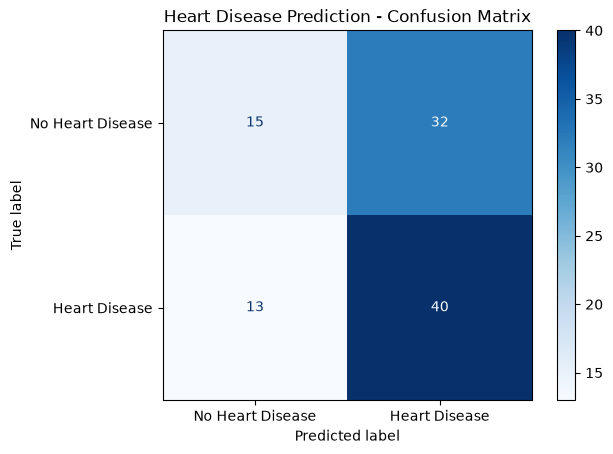

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Heart Disease', 'Heart Disease']
)

disp.plot(cmap='Blues')
plt.title('Heart Disease Prediction - Confusion Matrix')
plt.show()

In [18]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.32      0.40        47
           1       0.56      0.75      0.64        53

    accuracy                           0.55       100
   macro avg       0.55      0.54      0.52       100
weighted avg       0.55      0.55      0.53       100



In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Create a pipeline with scaling and Logistic Regression
scaled_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train the model
scaled_model.fit(X_train, y_train)

print("Scaled Logistic Regression model trained successfully!")

Scaled Logistic Regression model trained successfully!


In [20]:
# Make predictions with the scaled model
y_pred_scaled = scaled_model.predict(X_test)

# Calculate accuracy
scaled_accuracy = accuracy_score(y_test, y_pred_scaled)

print("Scaled Model Accuracy:", scaled_accuracy * 100, "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_scaled))

Scaled Model Accuracy: 56.00000000000001 %

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.32      0.41        47
           1       0.56      0.77      0.65        53

    accuracy                           0.56       100
   macro avg       0.56      0.55      0.53       100
weighted avg       0.56      0.56      0.54       100



In [21]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train the model
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [22]:
# Make predictions
y_pred_tree = tree_model.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy * 100, "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 47.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.46      0.74      0.57        47
           1       0.50      0.23      0.31        53

    accuracy                           0.47       100
   macro avg       0.48      0.49      0.44       100
weighted avg       0.48      0.47      0.43       100



In [23]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [24]:
# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 49.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.43      0.44        47
           1       0.52      0.55      0.53        53

    accuracy                           0.49       100
   macro avg       0.49      0.49      0.49       100
weighted avg       0.49      0.49      0.49       100



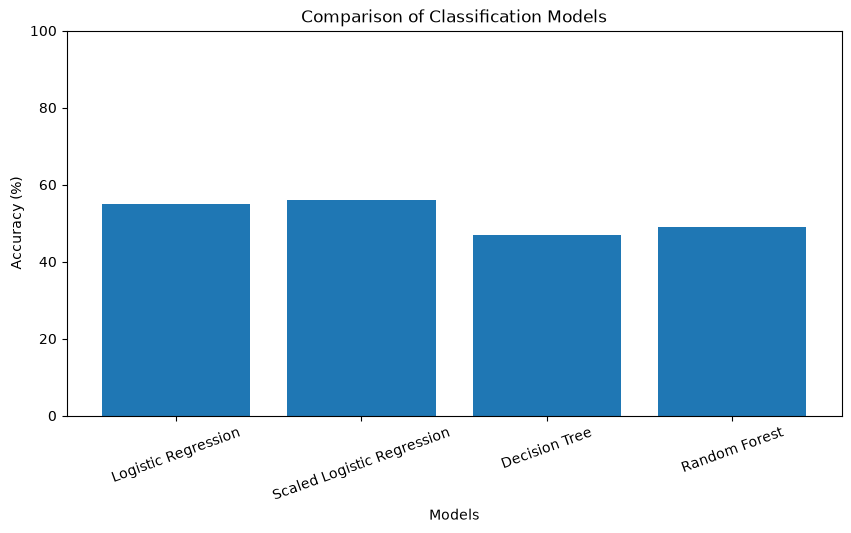

In [25]:
# Compare model accuracies

models = [
    'Logistic Regression',
    'Scaled Logistic Regression',
    'Decision Tree',
    'Random Forest'
]

accuracies = [
    accuracy * 100,
    scaled_accuracy * 100,
    tree_accuracy * 100,
    rf_accuracy * 100
]

plt.figure(figsize=(10, 5))
plt.bar(models, accuracies)

plt.title('Comparison of Classification Models')
plt.xlabel('Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.show()

heart_disease        1.000000
smoker               0.092282
physical_activity    0.051447
bmi                  0.033832
sex                  0.028212
cholesterol          0.008964
family_history      -0.001188
stress_level        -0.006209
diabetes            -0.016729
age                 -0.051803
blood_pressure      -0.067049
Name: heart_disease, dtype: float64


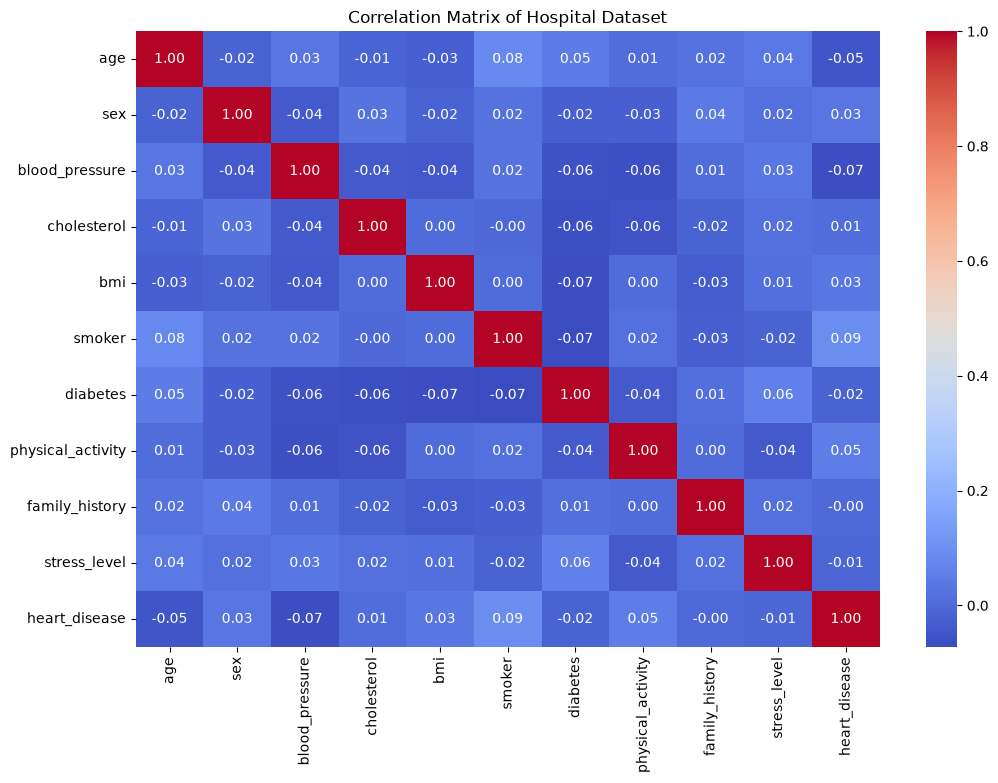

In [26]:
# Calculate correlations between numerical variables
correlation = df.corr(numeric_only=True)

# Display correlations with heart disease
print(correlation['heart_disease'].sort_values(ascending=False))

# Visualize the correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix of Hospital Dataset')
plt.show()

In [27]:
# Compare patient characteristics by heart disease status

comparison = df.groupby('heart_disease').mean(numeric_only=True)

print(comparison)

                     age       sex  blood_pressure  cholesterol        bmi  \
heart_disease                                                                
0              55.653846  0.452991      134.760684   221.081197  28.789744   
1              54.169173  0.481203      131.214286   221.868421  29.223308   

                 smoker  diabetes  physical_activity  family_history  \
heart_disease                                                          
0              0.482906  0.482906           1.970085        0.478632   
1              0.575188  0.466165           2.116541        0.477444   

               stress_level  
heart_disease                
0                  4.893162  
1                  4.860902  


In [28]:
from sklearn.ensemble import GradientBoostingClassifier

# Create Gradient Boosting model
gb_model = GradientBoostingClassifier(random_state=42)

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [29]:
# Make predictions
y_pred_gb = gb_model.predict(X_test)

# Calculate accuracy
gb_accuracy = accuracy_score(y_test, y_pred_gb)

print("Gradient Boosting Accuracy:", gb_accuracy * 100, "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 55.00000000000001 %

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.40      0.46        47
           1       0.56      0.68      0.62        53

    accuracy                           0.55       100
   macro avg       0.55      0.54      0.54       100
weighted avg       0.55      0.55      0.54       100



In [30]:
# Compare all five classification models

model_names = [
    'Logistic Regression',
    'Scaled Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'Gradient Boosting'
]

model_accuracies = [
    accuracy * 100,
    scaled_accuracy * 100,
    tree_accuracy * 100,
    rf_accuracy * 100,
    gb_accuracy * 100
]

# Create comparison table
model_comparison = pd.DataFrame({
    'Model': model_names,
    'Accuracy (%)': model_accuracies
})

print(model_comparison.sort_values(
    by='Accuracy (%)', ascending=False
))

                        Model  Accuracy (%)
1  Scaled Logistic Regression          56.0
0         Logistic Regression          55.0
4           Gradient Boosting          55.0
3               Random Forest          49.0
2               Decision Tree          47.0


             Feature  Importance
2     blood_pressure    0.194792
4                bmi    0.183926
3        cholesterol    0.179723
0                age    0.154741
9       stress_level    0.096779
7  physical_activity    0.076564
8     family_history    0.031250
5             smoker    0.027844
1                sex    0.027497
6           diabetes    0.026883


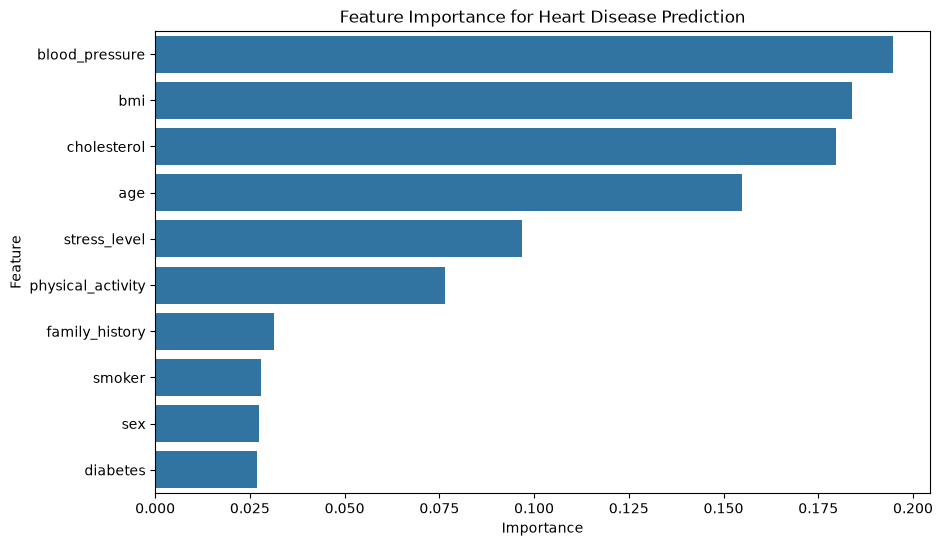

In [31]:
# Calculate feature importance
importance = rf_model.feature_importances_

# Create a feature importance table
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance for Heart Disease Prediction')
plt.show()

In [32]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline_model = DummyClassifier(strategy='most_frequent')

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.53


In [33]:
print(df.groupby('heart_disease').mean(numeric_only=True))

                     age       sex  blood_pressure  cholesterol        bmi  \
heart_disease                                                                
0              55.653846  0.452991      134.760684   221.081197  28.789744   
1              54.169173  0.481203      131.214286   221.868421  29.223308   

                 smoker  diabetes  physical_activity  family_history  \
heart_disease                                                          
0              0.482906  0.482906           1.970085        0.478632   
1              0.575188  0.466165           2.116541        0.477444   

               stress_level  
heart_disease                
0                  4.893162  
1                  4.860902  


In [34]:
print(pd.crosstab(df['smoker'], df['heart_disease'], normalize='index') * 100)

print("\nDiabetes:")
print(pd.crosstab(df['diabetes'], df['heart_disease'], normalize='index') * 100)

heart_disease          0          1
smoker                             
0              51.709402  48.290598
1              42.481203  57.518797

Diabetes:
heart_disease          0          1
diabetes                           
0              46.007605  53.992395
1              47.679325  52.320675


In [35]:
print("Sex:")
print(pd.crosstab(df['sex'], df['heart_disease'], normalize='index') * 100)

print("\nFamily History:")
print(pd.crosstab(df['family_history'], df['heart_disease'], normalize='index') * 100)

Sex:
heart_disease          0          1
sex                                
0              48.120301  51.879699
1              45.299145  54.700855

Family History:
heart_disease           0          1
family_history                      
0               46.743295  53.256705
1               46.861925  53.138075


In [36]:
from sklearn.metrics import roc_auc_score

y_prob = scaled_model.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc_score)

ROC-AUC Score: 0.5054195102368526


In [37]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', probability=True, random_state=42)
)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

c:\Users\Daniella Boni\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Accuracy: 0.56

Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.43      0.48        47
           1       0.57      0.68      0.62        53

    accuracy                           0.56       100
   macro avg       0.56      0.55      0.55       100
weighted avg       0.56      0.56      0.55       100



In [38]:
print(df['heart_disease'].value_counts())

print("\nTarget distribution:")
print(df['heart_disease'].value_counts(normalize=True) * 100)

heart_disease
1    266
0    234
Name: count, dtype: int64

Target distribution:
heart_disease
1    53.2
0    46.8
Name: proportion, dtype: float64


In [39]:
import joblib

joblib.dump(scaled_model, 'heart_disease_model.pkl')

print("Model saved successfully!")

Model saved successfully!
